# Base de datos HURTO A RESIDENCIAS y HURTO PERSONAS
- Fuente: Ministerio de Defensa

https://www.datos.gov.co/Seguridad-y-Defensa/HURTO-A-RESIDENCIAS/7mn7-vzqp/about_data

https://www.datos.gov.co/Seguridad-y-Defensa/HURTO-PERSONAS/4rxi-8m8d/about_data

In [ ]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sodapy import Socrata

sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams["figure.dpi"] = 300

## conexion a BD

In [7]:
# CONEXIÓN
APP_TOKEN = "zkj4BAQIZkr7n4t4NKzvLt5zq"

client = Socrata(
    "datos.gov.co",
    APP_TOKEN,
    timeout=120
)

DATASET = "7mn7-vzqp"

print("Conexión configurada correctamente")

Conexión configurada correctamente


In [8]:
# prueba comnexion 
prueba = client.get(DATASET, limit=5)

df_prueba = pd.DataFrame(prueba)

display(df_prueba)

,fecha_hecho,cod_depto,departamento,cod_muni,municipio,cantidad
0,2026-09-30T00:00:00.000,54,NORTE DE SANTANDER,54001,CUCUTA,1
1,2026-09-30T00:00:00.000,63,QUINDIO,63001,ARMENIA,1
2,2026-09-30T00:00:00.000,50,META,50001,VILLAVICENCIO,1
3,2026-09-30T00:00:00.000,11,BOGOTA D.C.,11001,BOGOTA D.C.,1
4,2026-09-30T00:00:00.000,76,VALLE DEL CAUCA,76364,JAMUNDI,1


In [59]:
# FUNCIÓN GENERAL DE EXTRACCIÓN

def extraer_bases_delitos(dataset, nombre, anios=[2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]):

    anios_sql = ", ".join(map(str, anios))

    datos = []
    limit = 50000
    offset = 0

    while True:

        chunk = client.get(
            dataset,
            select="""
                cod_muni AS codigo_dane,
                date_extract_y(fecha_hecho) AS anio,
                SUM(cantidad) AS casos
            """,
            where=f"date_extract_y(fecha_hecho) IN ({anios_sql})",
            group="cod_muni, date_extract_y(fecha_hecho)",
            order="anio, codigo_dane",
            limit=limit,
            offset=offset
        )

        if not chunk:
            break

        datos.extend(chunk)
        offset += len(chunk)

        print(f"{nombre}: {len(datos):,} registros")

        if len(chunk) < limit:
            break

    df = pd.DataFrame(datos)

    if not df.empty:
        df["anio"] = pd.to_numeric(df["anio"]).astype(int)
        df["casos"] = pd.to_numeric(df["casos"])

    print(f"{nombre} - Dimensiones: {df.shape}")

    return df

## Exploracion Dataframes

In [60]:
df_hurto_residencias = extraer_bases_delitos("7mn7-vzqp", "hurto_residencias")
df_hurto_personas = extraer_bases_delitos("4rxi-8m8d", "hurto_personas")

print("Dimensiones df_hurto_residencias:", df_hurto_residencias.shape)
print("\nAños:", sorted(df_hurto_residencias["anio"].unique()))
print("Dimensiones df_hurto_personas:", df_hurto_personas.shape)
print("\nAños:", sorted(df_hurto_personas["anio"].unique()))


hurto_residencias: 10,840 registros
hurto_residencias - Dimensiones: (10840, 3)
hurto_personas: 11,866 registros
hurto_personas - Dimensiones: (11866, 3)
Dimensiones df_hurto_residencias: (10840, 3)

Años: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Dimensiones df_hurto_personas: (11866, 3)

Años: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


In [61]:
display(df_hurto_residencias.head())
display(df_hurto_residencias.describe())

,codigo_dane,anio,casos
0,05001,2015,967
1,05002,2015,7
2,05021,2015,4
3,05030,2015,8
4,05031,2015,12


,anio,casos
count,10840.000000,10840.000000
mean,2020.550369,36.636716
std,3.351732,267.332518
min,2015.000000,1.000000
25%,2018.000000,2.000000
50%,2021.000000,6.000000
75%,2023.000000,17.000000
max,2026.000000,10022.000000


In [62]:
display(df_hurto_personas.head())
display(df_hurto_personas.describe())

,codigo_dane,anio,casos
0,05001,2015,7838
1,05002,2015,16
2,05021,2015,9
3,05030,2015,17
4,05031,2015,32


,anio,casos
count,11866.000000,11866.000000
mean,2020.578291,258.391960
std,3.410968,3571.140451
min,2015.000000,1.000000
25%,2018.000000,3.000000
50%,2021.000000,9.000000
75%,2024.000000,32.000000
max,2026.000000,158745.000000


### Pivoteo de los DF

In [63]:
# UNIFICAR BASES DE HURTO
df_hurto_residencias["tipo_hurto"] = "hurto_residencias"
df_hurto_personas["tipo_hurto"] = "hurto_personas"

df_hurtos_base = pd.concat( [df_hurto_residencias, df_hurto_personas], ignore_index=True)

# PIVOTAR
df_hurtos = (
    df_hurtos_base
    .pivot_table(
        index=["codigo_dane", "anio"],
        columns="tipo_hurto",
        values="casos",
        aggfunc="sum",
        #fill_value=0
    )
    .reset_index()
)

df_hurtos.columns.name = None

display(df_hurtos.head())
print("Dimensiones:", df_hurtos.shape)

,codigo_dane,anio,hurto_personas,hurto_residencias
0,05001,2015,7838.0,967.0
1,05001,2016,13425.0,970.0
2,05001,2017,17825.0,1809.0
3,05001,2018,21975.0,2135.0
4,05001,2019,27263.0,2159.0


Dimensiones: (12486, 4)


Importante: *fill_value=0* convierte en cero los cruces municipio-año que no tienen registros en una de las fuentes. Se decide conservar el nulo como ausencia de informacion, si existen ceros del origen se conservan

## Validaciones clave

In [64]:
print("fidelidad de la agrupacion:")
print("Hurto residencias:")
print(df_hurto_residencias["casos"].sum())

print("Hurto personas:")
print(df_hurto_personas["casos"].sum())

print("\nBase consolidada:")
print(df_hurtos[
    ["hurto_residencias", "hurto_personas"]
].sum())

fidelidad de la agrupacion:
Hurto residencias:
397142
Hurto personas:
3066079

Base consolidada:
hurto_residencias     397142.0
hurto_personas       3066079.0
dtype: float64


In [66]:
print("Totalidad - Valores por año:")

display(
    df_hurtos.groupby("anio").agg(
        municipios=("codigo_dane", "nunique"),
        hurto_personas=("hurto_personas", "sum"),
        hurto_residencias=("hurto_residencias", "sum")
    )
)

Totalidad - Valores por año:


,municipios,hurto_personas,hurto_residencias
anio,,,
2015,941,101448.0,21164.0
2016,1027,146864.0,24191.0
2017,1059,209781.0,46550.0
2018,1059,257069.0,47372.0
2019,1061,306836.0,46462.0
2020,1036,208037.0,33603.0
2021,1053,281416.0,33249.0
2022,1062,351680.0,34507.0
2023,1076,391005.0,35701.0


In [67]:
# Revisar disponibilidad por tipo de hurto
print(df_hurtos.isnull().sum())

# Porcentaje de cobertura
display(
    df_hurtos[["hurto_personas", "hurto_residencias"]]
    .notna()
    .mean()
    .mul(100)
    .round(2)
)

codigo_dane             0
anio                    0
hurto_personas        620
hurto_residencias    1646
dtype: int64


hurto_personas       95.03
hurto_residencias    86.82
dtype: float64

## Calidad de datos 

In [68]:
#creacion funcion 
def calidad_datos(df, nombre_fuente):

    print("=" * 60)
    print(f"AUDITORÍA DE CALIDAD: {nombre_fuente}")
    print("=" * 60)

    # 1. TOTALIDAD
    print("\n1. TOTALIDAD")

    print("Registros:", len(df))
    print("Variables:", df.shape[1])
    print("Nulos por variable:")
    display(df.isnull().sum().to_frame("Nulos"))

    print("\nCompletitud (%):")
    display(((1 - df.isnull().mean()) * 100).round(2))

    # 2. CONSISTENCIA
    print("\n2. CONSISTENCIA")

    print("Duplicados exactos:", df.duplicated().sum())

    if {"codigo_dane", "anio"}.issubset(df.columns):
        print(
            "Duplicados municipio-año:",
            df.duplicated(["codigo_dane", "anio"]).sum()
        )

    # 3. CLARIDAD
    print("\n3. CLARIDAD")

    print("Nombres de variables:", df.columns.tolist())
    print("Variables sin nombre:", df.columns[df.columns.str.strip() == ""].tolist())

    # 4. FORMATO
    print("\n4. FORMATO")

    display(df.dtypes.to_frame("Tipo de dato"))

    if "codigo_dane" in df.columns:
        codigos = df["codigo_dane"].astype("string")
        invalidos = ~codigos.str.fullmatch(r"\d{5}", na=False)

        print("Códigos DANE con formato inválido:", invalidos.sum())

    if "anio" in df.columns:
        anios = sorted(df["anio"].dropna().astype(int).unique().tolist())

        print(f"Años disponibles ({len(anios)}): {', '.join(map(str, anios))}")

    # 5. GRANULARIDAD
    print("\n5. GRANULARIDAD")

    if {"codigo_dane", "anio"}.issubset(df.columns):
        print("Granularidad esperada: municipio-año")
        print(
            "Llave única:",
            df.duplicated(["codigo_dane", "anio"]).sum() == 0
        )

        print("Municipios:", df["codigo_dane"].nunique())
        print("Años:", df["anio"].nunique())

    # 6. FIDELIDAD Y 7. EXACTITUD
    print("\n6. FIDELIDAD Y 7. EXACTITUD")

    columnas_casos = [
        col for col in df.columns
        if col == "casos" or col.startswith("hurto_")
    ]

    for col in columnas_casos:

        valores = pd.to_numeric(df[col], errors="coerce")

        print(f"\nVariable: {col}")
        print("Valores no numéricos:", valores.isna().sum() - df[col].isna().sum())
        print("Valores negativos:", (valores < 0).sum())
        print("Total de casos:", valores.sum())

In [69]:
# Bases originales
calidad_datos(df_hurto_residencias, "Hurto a residencias")

AUDITORÍA DE CALIDAD: Hurto a residencias

1. TOTALIDAD
Registros: 10840
Variables: 4
Nulos por variable:


,Nulos
codigo_dane,0
anio,0
casos,0
tipo_hurto,0



Completitud (%):


codigo_dane    100.0
anio           100.0
casos          100.0
tipo_hurto     100.0
dtype: float64


2. CONSISTENCIA
Duplicados exactos: 0
Duplicados municipio-año: 0

3. CLARIDAD
Nombres de variables: ['codigo_dane', 'anio', 'casos', 'tipo_hurto']
Variables sin nombre: []

4. FORMATO


,Tipo de dato
codigo_dane,object
anio,int64
casos,int64
tipo_hurto,object


Códigos DANE con formato inválido: 0
Años disponibles (12): 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026

5. GRANULARIDAD
Granularidad esperada: municipio-año
Llave única: True
Municipios: 1103
Años: 12

6. FIDELIDAD Y 7. EXACTITUD

Variable: casos
Valores no numéricos: 0
Valores negativos: 0
Total de casos: 397142


In [70]:
# Bases originales
calidad_datos(df_hurto_personas, "Hurto a personas")

AUDITORÍA DE CALIDAD: Hurto a personas

1. TOTALIDAD
Registros: 11866
Variables: 4
Nulos por variable:


,Nulos
codigo_dane,0
anio,0
casos,0
tipo_hurto,0



Completitud (%):


codigo_dane    100.0
anio           100.0
casos          100.0
tipo_hurto     100.0
dtype: float64


2. CONSISTENCIA
Duplicados exactos: 0
Duplicados municipio-año: 0

3. CLARIDAD
Nombres de variables: ['codigo_dane', 'anio', 'casos', 'tipo_hurto']
Variables sin nombre: []

4. FORMATO


,Tipo de dato
codigo_dane,object
anio,int64
casos,int64
tipo_hurto,object


Códigos DANE con formato inválido: 0
Años disponibles (12): 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026

5. GRANULARIDAD
Granularidad esperada: municipio-año
Llave única: True
Municipios: 1110
Años: 12

6. FIDELIDAD Y 7. EXACTITUD

Variable: casos
Valores no numéricos: 0
Valores negativos: 0
Total de casos: 3066079


In [71]:
# Base consolidada
calidad_datos(df_hurtos, "Hurtos consolidados")

AUDITORÍA DE CALIDAD: Hurtos consolidados

1. TOTALIDAD
Registros: 12486
Variables: 4
Nulos por variable:


,Nulos
codigo_dane,0
anio,0
hurto_personas,620
hurto_residencias,1646



Completitud (%):


codigo_dane          100.00
anio                 100.00
hurto_personas        95.03
hurto_residencias     86.82
dtype: float64


2. CONSISTENCIA
Duplicados exactos: 0
Duplicados municipio-año: 0

3. CLARIDAD
Nombres de variables: ['codigo_dane', 'anio', 'hurto_personas', 'hurto_residencias']
Variables sin nombre: []

4. FORMATO


,Tipo de dato
codigo_dane,object
anio,int64
hurto_personas,float64
hurto_residencias,float64


Códigos DANE con formato inválido: 0
Años disponibles (12): 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026

5. GRANULARIDAD
Granularidad esperada: municipio-año
Llave única: True
Municipios: 1112
Años: 12

6. FIDELIDAD Y 7. EXACTITUD

Variable: hurto_personas
Valores no numéricos: 0
Valores negativos: 0
Total de casos: 3066079.0

Variable: hurto_residencias
Valores no numéricos: 0
Valores negativos: 0
Total de casos: 397142.0


La base consolidada tiene 12486 registros y cuatro variables, con valores nulos, no hay duplicados ni problemas identificados en el formato de los códigos DIVIPOLA.

- Se decide no imputar automáticamente con cero, media o mediana.

## Limpieza de datos

Consideraciones:
- Cada tipo de hurto es un fenomeno independiente y no deberia existir una relacion de orden entre ellos

-  en datos de criminalidad, un municipio con cero casos no necesariamente es equivalente a un municipio sin información. Tampoco debemos eliminar valores altos solo por ser extremos: pueden representar municipios con mayor incidencia delictiva.

- Outliers: un municipio con muchos hurtos no necesariamente tiene datos incorrectos. Puede ser precisamente un municipio relevante para el estudio.

- Imputación: no debemos reemplazar automáticamente los municipios sin información por promedios nacionales. Esto podría alterar la clasificación de los municipios.

- los casos absolutos de hurto deben interpretarse considerando el tamaño poblacional. Más adelante podremos evaluar tasas por población, si contamos con denominadores compatibles.

- Rangos válidos: Casos mayores o iguales a cero y años dentro de 2018–2020.

- Tipos inconsistentes: Año y casos numéricos; DIVIPOLA como texto de cinco dígitos.

- Valores extremos: Evaluación mediante IQR, sin eliminación.

- Interrelaciones: Coherencia entre municipio, año y los dos tipos de hurto.



In [72]:
# VALIDACIÓN DE LAS FUENTES ORIGINALES

fuentes = {
    "hurto_personas": df_hurto_personas,
    "hurto_residencias": df_hurto_residencias
}

for nombre, df in fuentes.items():

    print(f"\n--- {nombre.upper()} ---")

    # Espacios vacíos
    print("Espacios vacíos:", df.astype("string").apply(lambda x: x.str.strip().eq("").sum()).sum())

    # Tipos y valores no numéricos
    for col in ["anio", "casos"]:
        valores = pd.to_numeric(df[col], errors="coerce")
        print(f"{col} - No numéricos:", (valores.isna() & df[col].notna()).sum())

    # Rangos válidos
    print("Años fuera del rango normal (1900-2099):", (~df["anio"].between(1900, 2099)).sum())
    print("Años fuera del periodo de descarga (2015-2026):",(~df["anio"].between(2015, 2026)).sum())
    print("Casos negativos:", (pd.to_numeric(df["casos"], errors="coerce") < 0).sum())

    # Códigos DIVIPOLA
    codigos = df["codigo_dane"].astype("string")
    print("DIVIPOLA inválidos:", (~codigos.str.fullmatch(r"\d{5}", na=False)).sum())

    # Granularidad
    print("Duplicados municipio-año:", df.duplicated(["codigo_dane", "anio"]).sum())


--- HURTO_PERSONAS ---
Espacios vacíos: 0
anio - No numéricos: 0
casos - No numéricos: 0
Años fuera del rango normal (1900-2099): 0
Años fuera del periodo de descarga (2015-2026): 0
Casos negativos: 0
DIVIPOLA inválidos: 0
Duplicados municipio-año: 0

--- HURTO_RESIDENCIAS ---
Espacios vacíos: 0
anio - No numéricos: 0
casos - No numéricos: 0
Años fuera del rango normal (1900-2099): 0
Años fuera del periodo de descarga (2015-2026): 0
Casos negativos: 0
DIVIPOLA inválidos: 0
Duplicados municipio-año: 0


In [73]:
# IDENTIFICACIÓN DE OUTLIERS CON IQR Indice intercuartilico

for col in ["casos"]:
    for nombre, df in fuentes.items():

        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1

        limite_inf = q1 - 1.5 * iqr
        limite_sup = q3 + 1.5 * iqr

        outliers = df[(df[col] < limite_inf) | (df[col] > limite_sup)]

        print(f"\n{nombre} - {col}")
        print("Límite inferior:", limite_inf)
        print("Límite superior:", limite_sup)
        print("Valores extremos:", len(outliers))
        print("Porcentaje:", round(len(outliers) / len(df) * 100, 2), "%")



hurto_personas - casos
Límite inferior: -40.5
Límite superior: 75.5
Valores extremos: 1725
Porcentaje: 14.54 %

hurto_residencias - casos
Límite inferior: -20.5
Límite superior: 39.5
Valores extremos: 1412
Porcentaje: 13.03 %


El método IQR identifica como extremos los municipios-año que superan 75 casos de hurto a personas o 39,5 casos de hurto a residencias.


el límite inferior del IQR no identifica observaciones anómalas por ese lado.

La proporción de valores extremos es relativamente alta. Esto puede reflejar:

- Concentración de actividad delictiva en municipios de mayor tamaño.
- Diferencias demográficas y poblacionales.

In [55]:
# VALIDACIÓN DE INTERRELACIONES

llaves_personas = set(zip(df_hurto_personas["codigo_dane"], df_hurto_personas["anio"]))
llaves_residencias = set(zip(df_hurto_residencias["codigo_dane"], df_hurto_residencias["anio"]))

print("Municipio-año en ambas fuentes:", len(llaves_personas & llaves_residencias))
print("Solo hurto personas:", len(llaves_personas - llaves_residencias))
print("Solo hurto residencias:", len(llaves_residencias - llaves_personas))

Municipio-año en ambas fuentes: 8781
Solo hurto personas: 1230
Solo hurto residencias: 507


In [74]:
# Cobertura de hurtos por año
cobertura_anual = (
    df_hurtos
    .assign(
        cobertura=lambda x: np.select(
            [
                x["hurto_personas"].notna() & x["hurto_residencias"].notna(),
                x["hurto_personas"].notna(),
                x["hurto_residencias"].notna()
            ],
            [
                "Ambas fuentes",
                "Solo personas",
                "Solo residencias"
            ],
            default="Sin información"
        )
    )
    .groupby(["anio", "cobertura"])
    .size()
    .unstack(fill_value=0)
)

display(cobertura_anual)

cobertura,Ambas fuentes,Solo personas,Solo residencias
anio,,,
2015,675,193,73
2016,764,223,40
2017,887,98,74
2018,909,75,75
2019,921,91,49
2020,842,122,72
2021,890,115,48
2022,907,123,32
2023,912,134,30


Decisión metodológica final: no se realizará eliminación general, imputación estadística ni imputación aleatoria. Se conservarán los valores extremos y se mantendrán los registros ausentes como datos no disponibles hasta verificar su significado en las fuentes originales. La limpieza se concentrará en la estandarización de variables, validación de rangos, filtrado temporal y control de la integridad de la información.




### Decisiones de limpieza


| Técnica / Criterio | Decisión | Justificación |
| --- | --- | --- |
| Eliminación general de registros | No aplicar | No se identificaron registros nulos ni duplicados que justifiquen una eliminación general. |
| Eliminación de duplicados | No aplicar | No existen duplicados exactos ni duplicados en la llave municipio-año. |
| Imputación estadística | No aplicar | No se conoce con certeza si los registros ausentes representan cero casos o falta de información. |
| Imputación aleatoria | No aplicar | Introduciría valores artificiales que podrían distorsionar la caracterización de seguridad municipal. |
| Tratamiento de valores extremos (Outliers) | No eliminar | Los valores extremos pueden representar concentraciones reales de criminalidad y son relevantes para evaluar el riesgo territorial. |
| Estandarización de DIVIPOLA | Aplicar | Garantiza uniformidad de la llave territorial mediante códigos de texto de cinco dígitos. |
| Validación de tipos de datos | Aplicar | Asegura que los años y conteos de hurtos tengan formatos numéricos adecuados. |
| Validación de rangos | Aplicar | Los conteos deben ser iguales o superiores a cero y los años deben corresponder al periodo de estudio. |
| Filtrado temporal | Aplicar | Se conservarán únicamente los registros de 2018, 2019 y 2020, según la ventana temporal definida para el proyecto. |
| Tratamiento de registros ausentes entre fuentes | Conservar como NaN | No deben interpretarse automáticamente como cero casos, hasta verificar su significado. |
| Validación de cobertura territorial y temporal | Aplicar | Permite identificar diferencias en la disponibilidad de información entre municipios y años. |
| Verificación de fidelidad | Aplicar | Se compararán los totales de las fuentes originales con los resultados de la consolidación para garantizar la conservación de los registros. |

In [53]:
# LIMPIEZA DE BASE CONSOLIDADA DE HURTOS
df_hurtos_limpio = df_hurtos.copy()

# 1. Estandarizar codigo DIVIPOLA
print("Estandarizar codigo DIVIPOLA")
df_hurtos_limpio["codigo_dane"] = df_hurtos_limpio["codigo_dane"].astype(str).str.strip().str.zfill(5)

# 2. Validar tipos de datos
print("Validar tipos de datos")
df_hurtos_limpio["anio"] = pd.to_numeric(df_hurtos_limpio["anio"], errors="raise").astype(int)

columnas_hurtos = ["hurto_personas", "hurto_residencias"]

for col in columnas_hurtos:
    df_hurtos_limpio[col] = pd.to_numeric(df_hurtos_limpio[col], errors="raise")

# 3. Filtrar ventana temporal del proyecto
#print("Filtrar ventana temporal del proyecto")
#df_hurtos_limpio = df_hurtos_limpio[df_hurtos_limpio["anio"].between(2018, 2020)].copy()

# 4. Ordenar información
df_hurtos_limpio = df_hurtos_limpio.sort_values(["codigo_dane", "anio"]).reset_index(drop=True)

# 5. Verificar resultados
print("Dimensiones:", df_hurtos_limpio.shape)
print("Años:", sorted(df_hurtos_limpio["anio"].unique()))
print("Municipios:", df_hurtos_limpio["codigo_dane"].nunique())
print("Duplicados:", df_hurtos_limpio.duplicated(["codigo_dane", "anio"]).sum())
display(df_hurtos_limpio.head())

Estandarizar codigo DIVIPOLA
Validar tipos de datos
Dimensiones: (10518, 4)
Años: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Municipios: 1110
Duplicados: 0


,codigo_dane,anio,hurto_personas,hurto_residencias
0,05001,2017,17825.0,1809.0
1,05001,2018,21975.0,2135.0
2,05001,2019,27263.0,2159.0
3,05001,2020,17776.0,1703.0
4,05001,2021,23703.0,1665.0


### Conclusiones

Considerando que el objetivo del proyecto es identificar municipios con condiciones favorables para la estructuración de proyectos inmobiliarios, se determinó que asignar automáticamente valores cero a los registros ausentes podría generar una interpretación incorrecta de las condiciones de seguridad territorial.

Se identificaron valores extremos mediante el método IQR: 1.456 registros (14,54%) en hurto a personas y 1.241 (13,36%) en hurto a residencias. Se decidió conservarlos porque pueden representar concentraciones reales de delitos entre municipios y eliminarlos podría distorsionar el análisis.

En cuanto a la cobertura, se encontraron 8.781 combinaciones municipio-año con información en ambas fuentes, 1.230 únicamente en hurto a personas y 507 únicamente en hurto a residencias, alcanzando una cobertura conjunta del 83,49%.

Estas diferencias muestran que la información no está completa de manera uniforme. Por ello, se conservaron los datos faltantes sin realizar imputaciones automáticas, evitando introducir sesgos hasta determinar su significado y tratamiento en el análisis final.

## Entendimiento de los datos

Proponemos validar:
- ¿Qué municipios presentan mayores niveles de hurtos?
- ¿Cómo evoluciona la criminalidad entre 2018 y 2020?
- ¿Existen diferencias entre el comportamiento del hurto a personas y el hurto a residencias?
- ¿Qué municipios presentan perfiles similares de seguridad?
- ¿Cómo puede la seguridad complementar la identificación de municipios atractivos para desarrollar proyectos de vivienda?


importante: no debemos confundir el número absoluto de hurtos con el nivel de riesgo de un municipio. Un municipio grande puede presentar más casos simplemente por tener más población. Por eso, las tasas por población serán especialmente relevantes para el análisis inmobiliario.



In [77]:
# ==============================================================================
# 3. ENTENDIMIENTO DE DATOS - EDA NUMÉRICO Y GRÁFICO 
# Filtrar periodo de estudio
df_eda = df_hurtos_limpio.copy()

print("Dimensiones:", df_eda.shape)
print("Años:", sorted(df_eda["anio"].unique().tolist()))
print("Municipios:", df_eda["codigo_dane"].nunique())

# Estadísticas descriptivas
columnas = ["hurto_personas", "hurto_residencias"]

estadisticas = df_eda[columnas].describe().T
estadisticas["mediana"] = df_eda[columnas].median()
estadisticas["asimetria"] = df_eda[columnas].skew()
estadisticas["nulos"] = df_eda[columnas].isnull().sum()

display(estadisticas.round(2))

Dimensiones: (10518, 4)
Años: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
Municipios: 1110


,count,mean,std,min,25%,50%,75%,max,mediana,asimetria,nulos
hurto_personas,10011.0,281.47,3851.29,1.0,3.0,9.0,33.0,158745.0,9.0,29.81,507
hurto_residencias,9288.0,37.88,281.95,1.0,2.0,6.0,17.0,10022.0,6.0,25.99,1230


### Distribuciones

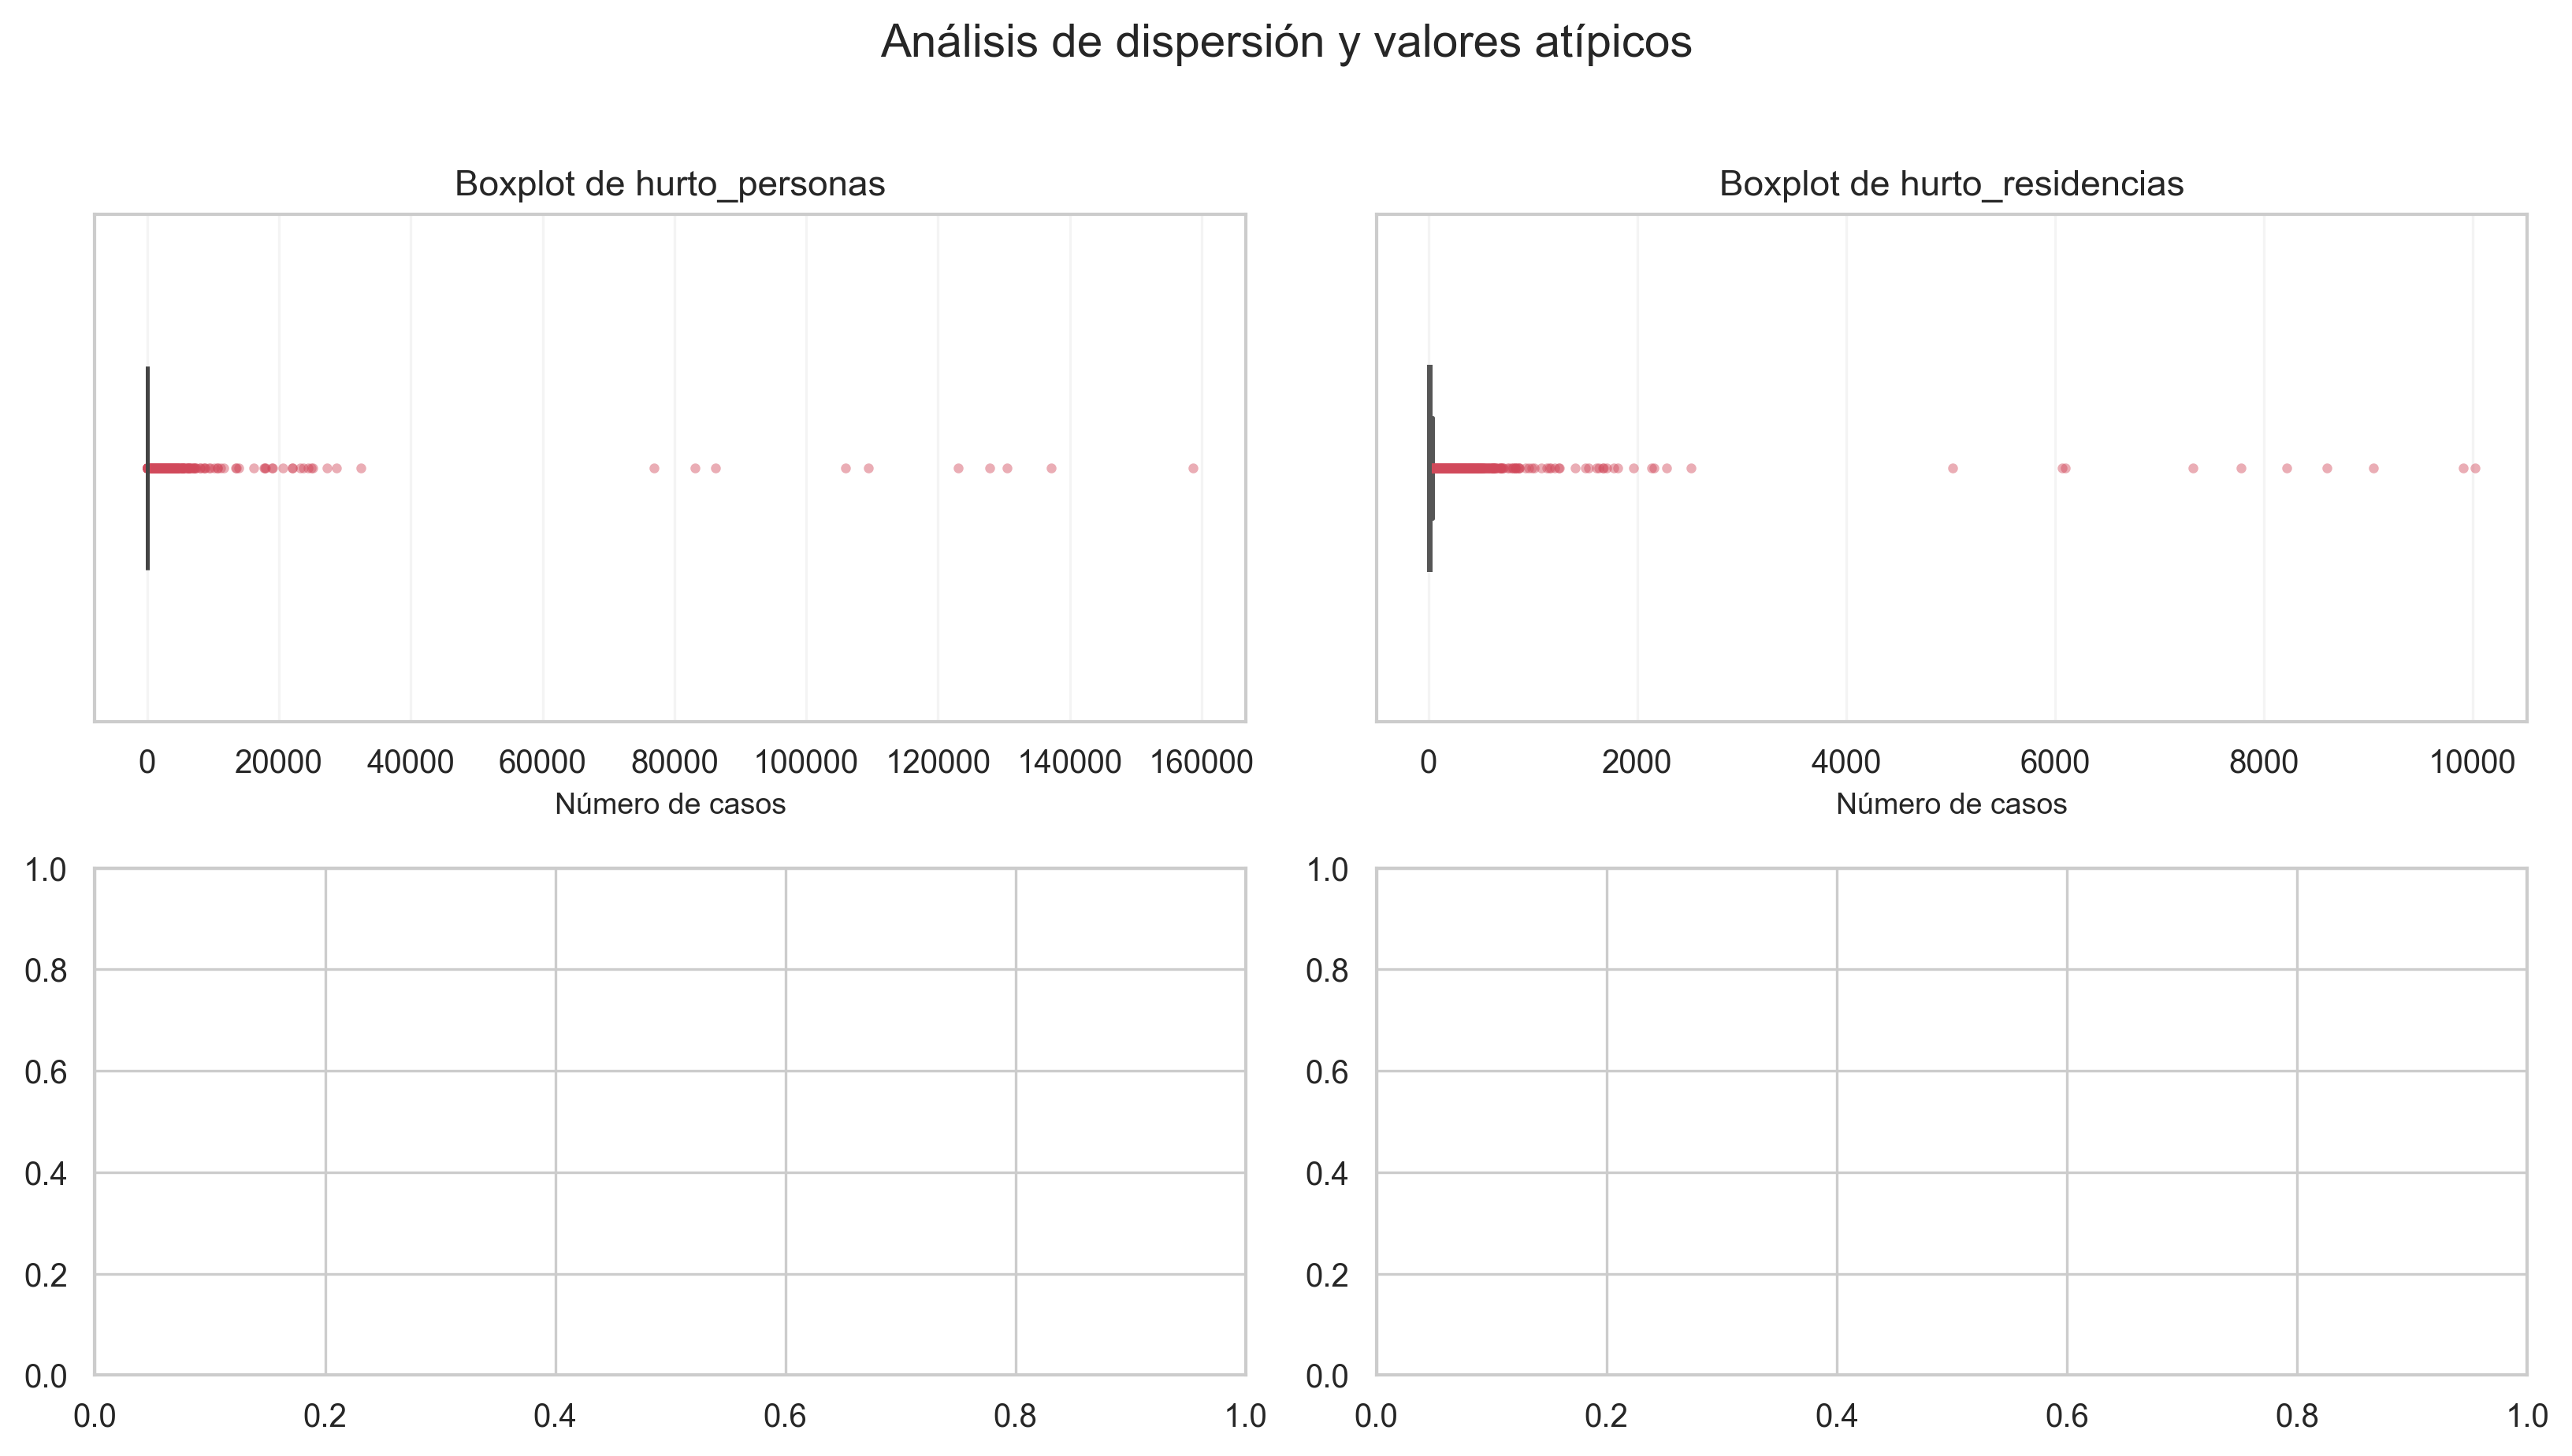

In [94]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))

colores = ["#3977A8", "#E09F3E", "#4C956C", "#9B72AA"]

for i, col in enumerate(columnas):
    ax = axes[i // 2, i % 2]
    datos = df_eda[col].dropna()

    sns.boxplot(
        x=datos,
        color=colores[i],
        width=0.4,
        linewidth=1.2,
        flierprops=dict(
            marker="o",
            markerfacecolor="#D1495B",
            markersize=3,
            alpha=0.45,
            markeredgecolor="none"
        ),
        ax=ax
    )

    ax.set_title(f"Boxplot de {col}", fontsize=11)
    ax.set_xlabel("Número de casos", fontsize=9)
    ax.grid(axis="x", alpha=0.2)

plt.suptitle("Análisis de dispersión y valores atípicos", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [79]:
# Evolución anual y cobertura
evolucion = df_eda.groupby("anio").agg(
    hurto_personas=("hurto_personas", "sum"),
    hurto_residencias=("hurto_residencias", "sum"),
    municipios_personas=("hurto_personas", "count"),
    municipios_residencias=("hurto_residencias", "count")
).reset_index()

display(evolucion)

,anio,hurto_personas,hurto_residencias,municipios_personas,municipios_residencias
0,2017,209781.0,46550.0,985,961
1,2018,257069.0,47372.0,984,984
2,2019,306836.0,46462.0,1012,970
3,2020,208037.0,33603.0,964,914
4,2021,281416.0,33249.0,1005,938
5,2022,351680.0,34507.0,1030,939
6,2023,391005.0,35701.0,1046,942
7,2024,316216.0,29662.0,1009,924
8,2025,289374.0,25813.0,1010,891
9,2026,206353.0,18868.0,966,825


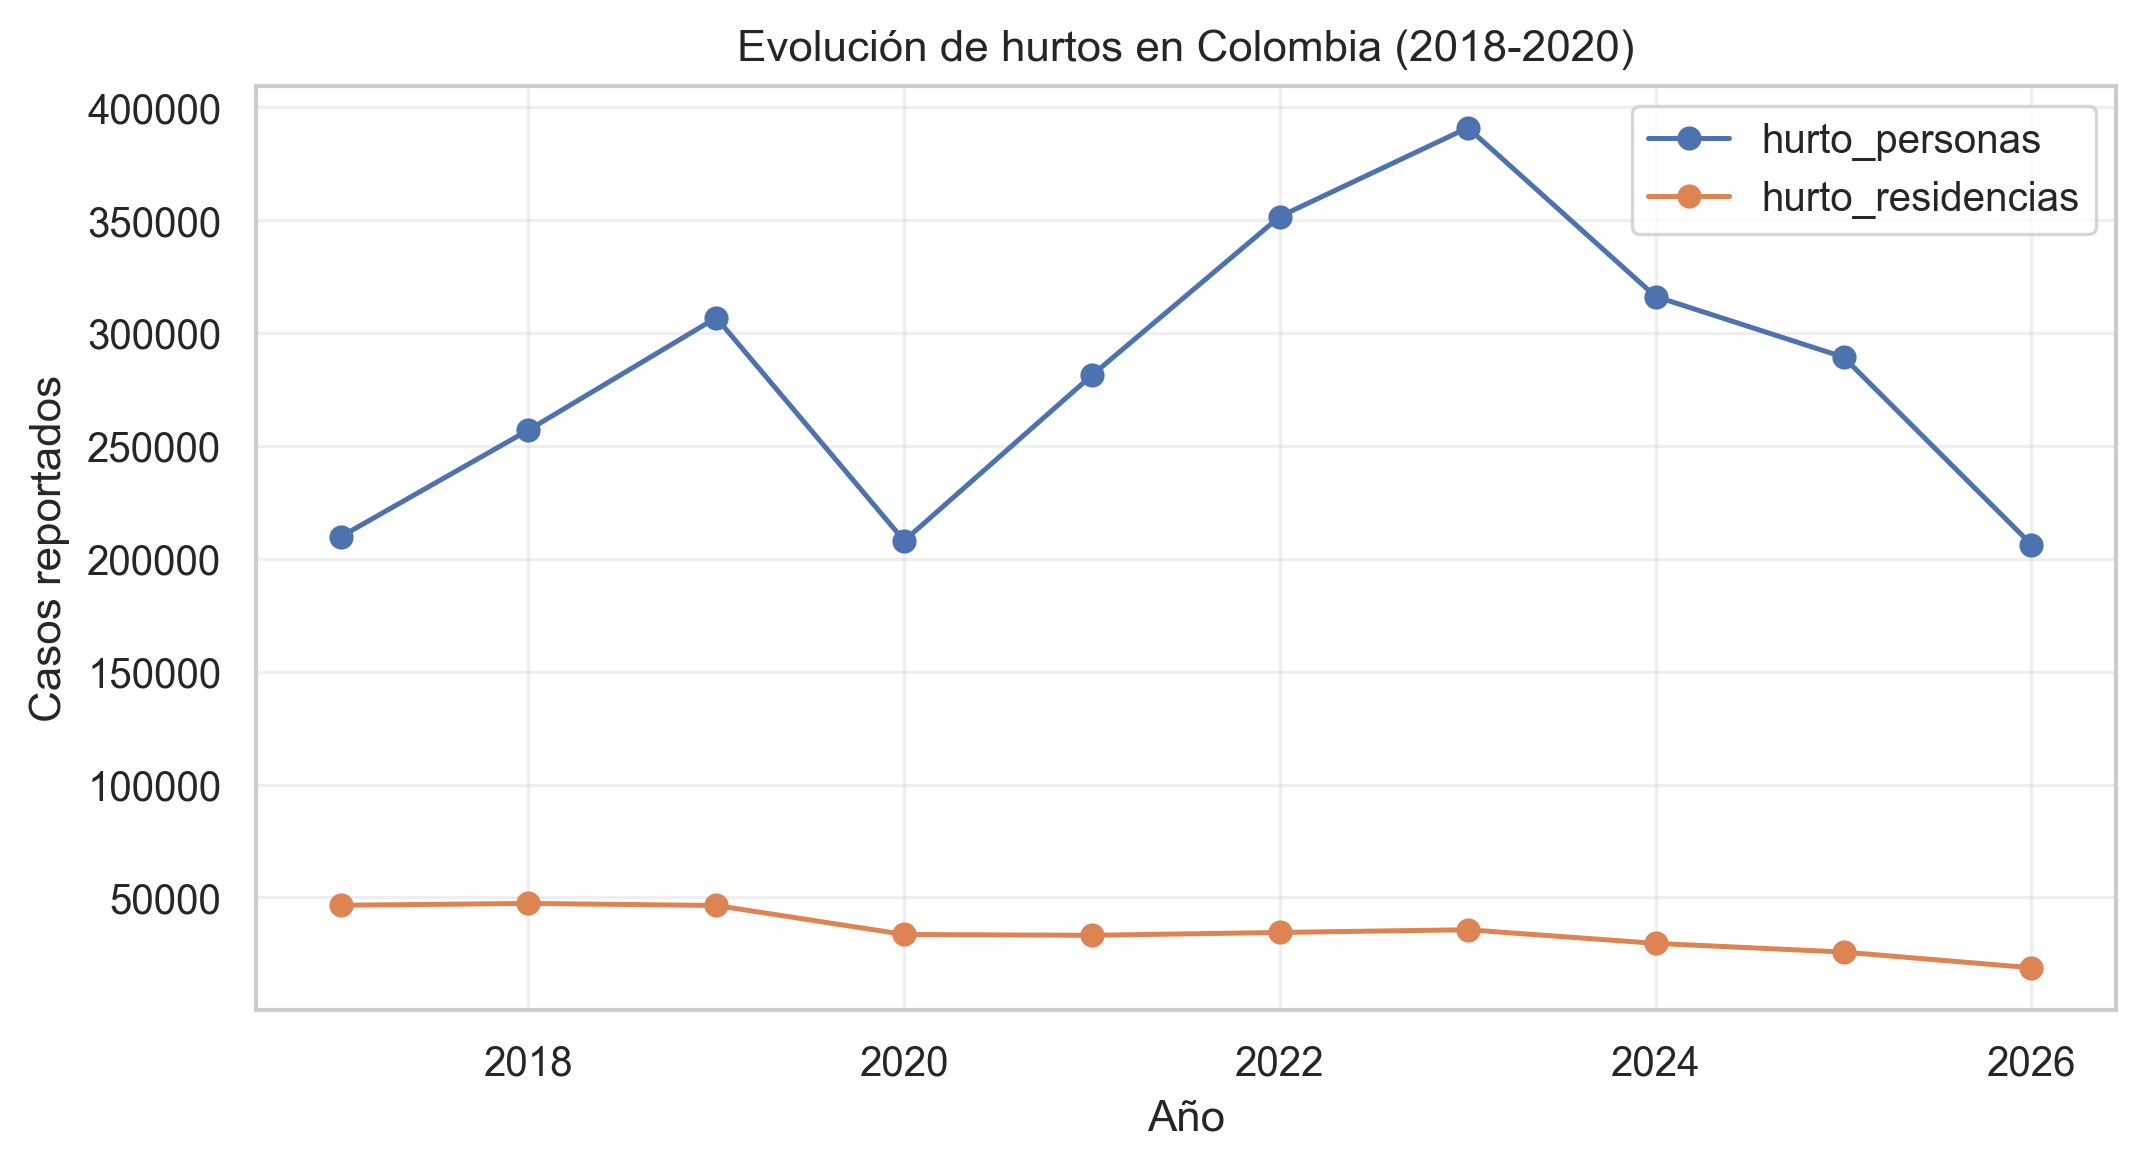

In [85]:
# Gráfico de evolución
evolucion.plot(
    x="anio",
    y=["hurto_personas", "hurto_residencias"],
    marker="o",
    figsize=(8, 4)
)

plt.title("Evolución de hurtos en Colombia (2018-2020)")
plt.xlabel("Año")
plt.ylabel("Casos reportados")
plt.grid(alpha=0.3)
plt.show()

### Tipos de hurto  relacion

,hurto_personas,hurto_residencias
hurto_personas,1.000,0.942
hurto_residencias,0.942,1.000


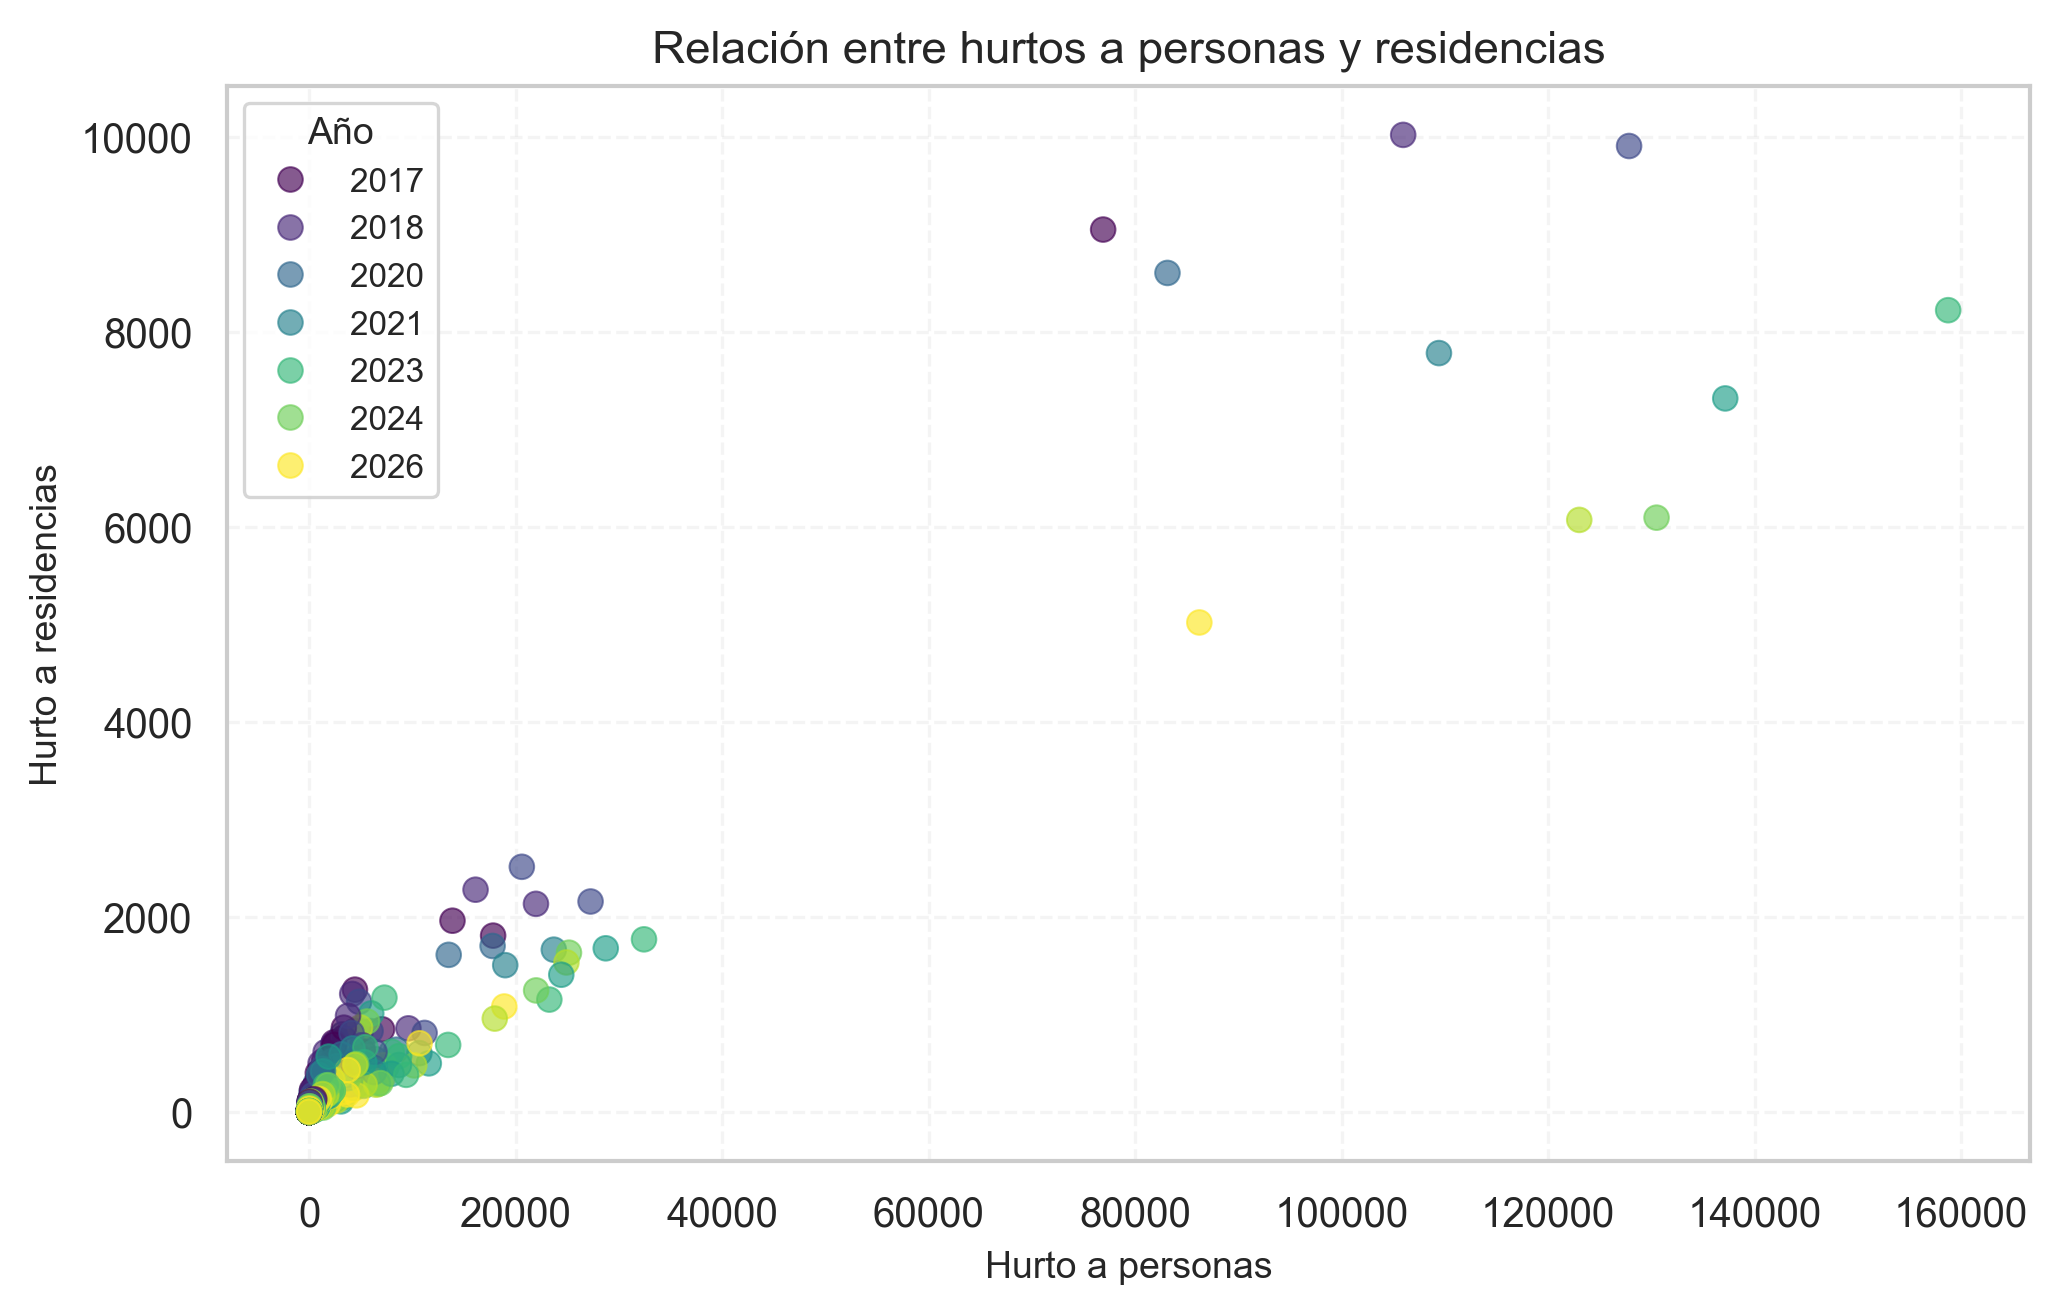

In [84]:
# Correlación entre tipos de hurto
correlacion = df_eda[columnas].corr(method="pearson")

display(correlacion.round(3))

# Relación entre los dos tipos de hurto
plt.figure(figsize=(7, 4.5))

sns.scatterplot(
    data=df_eda,
    x="hurto_personas",
    y="hurto_residencias",
    hue="anio",
    palette="viridis",
    alpha=0.65,
    s=35,
    edgecolor=None
)

plt.title("Relación entre hurtos a personas y residencias", fontsize=11)
plt.xlabel("Hurto a personas", fontsize=9)
plt.ylabel("Hurto a residencias", fontsize=9)

plt.legend(title="Año", fontsize=8, title_fontsize=9)
plt.grid(alpha=0.2, linestyle="--")
plt.tight_layout()
plt.show()

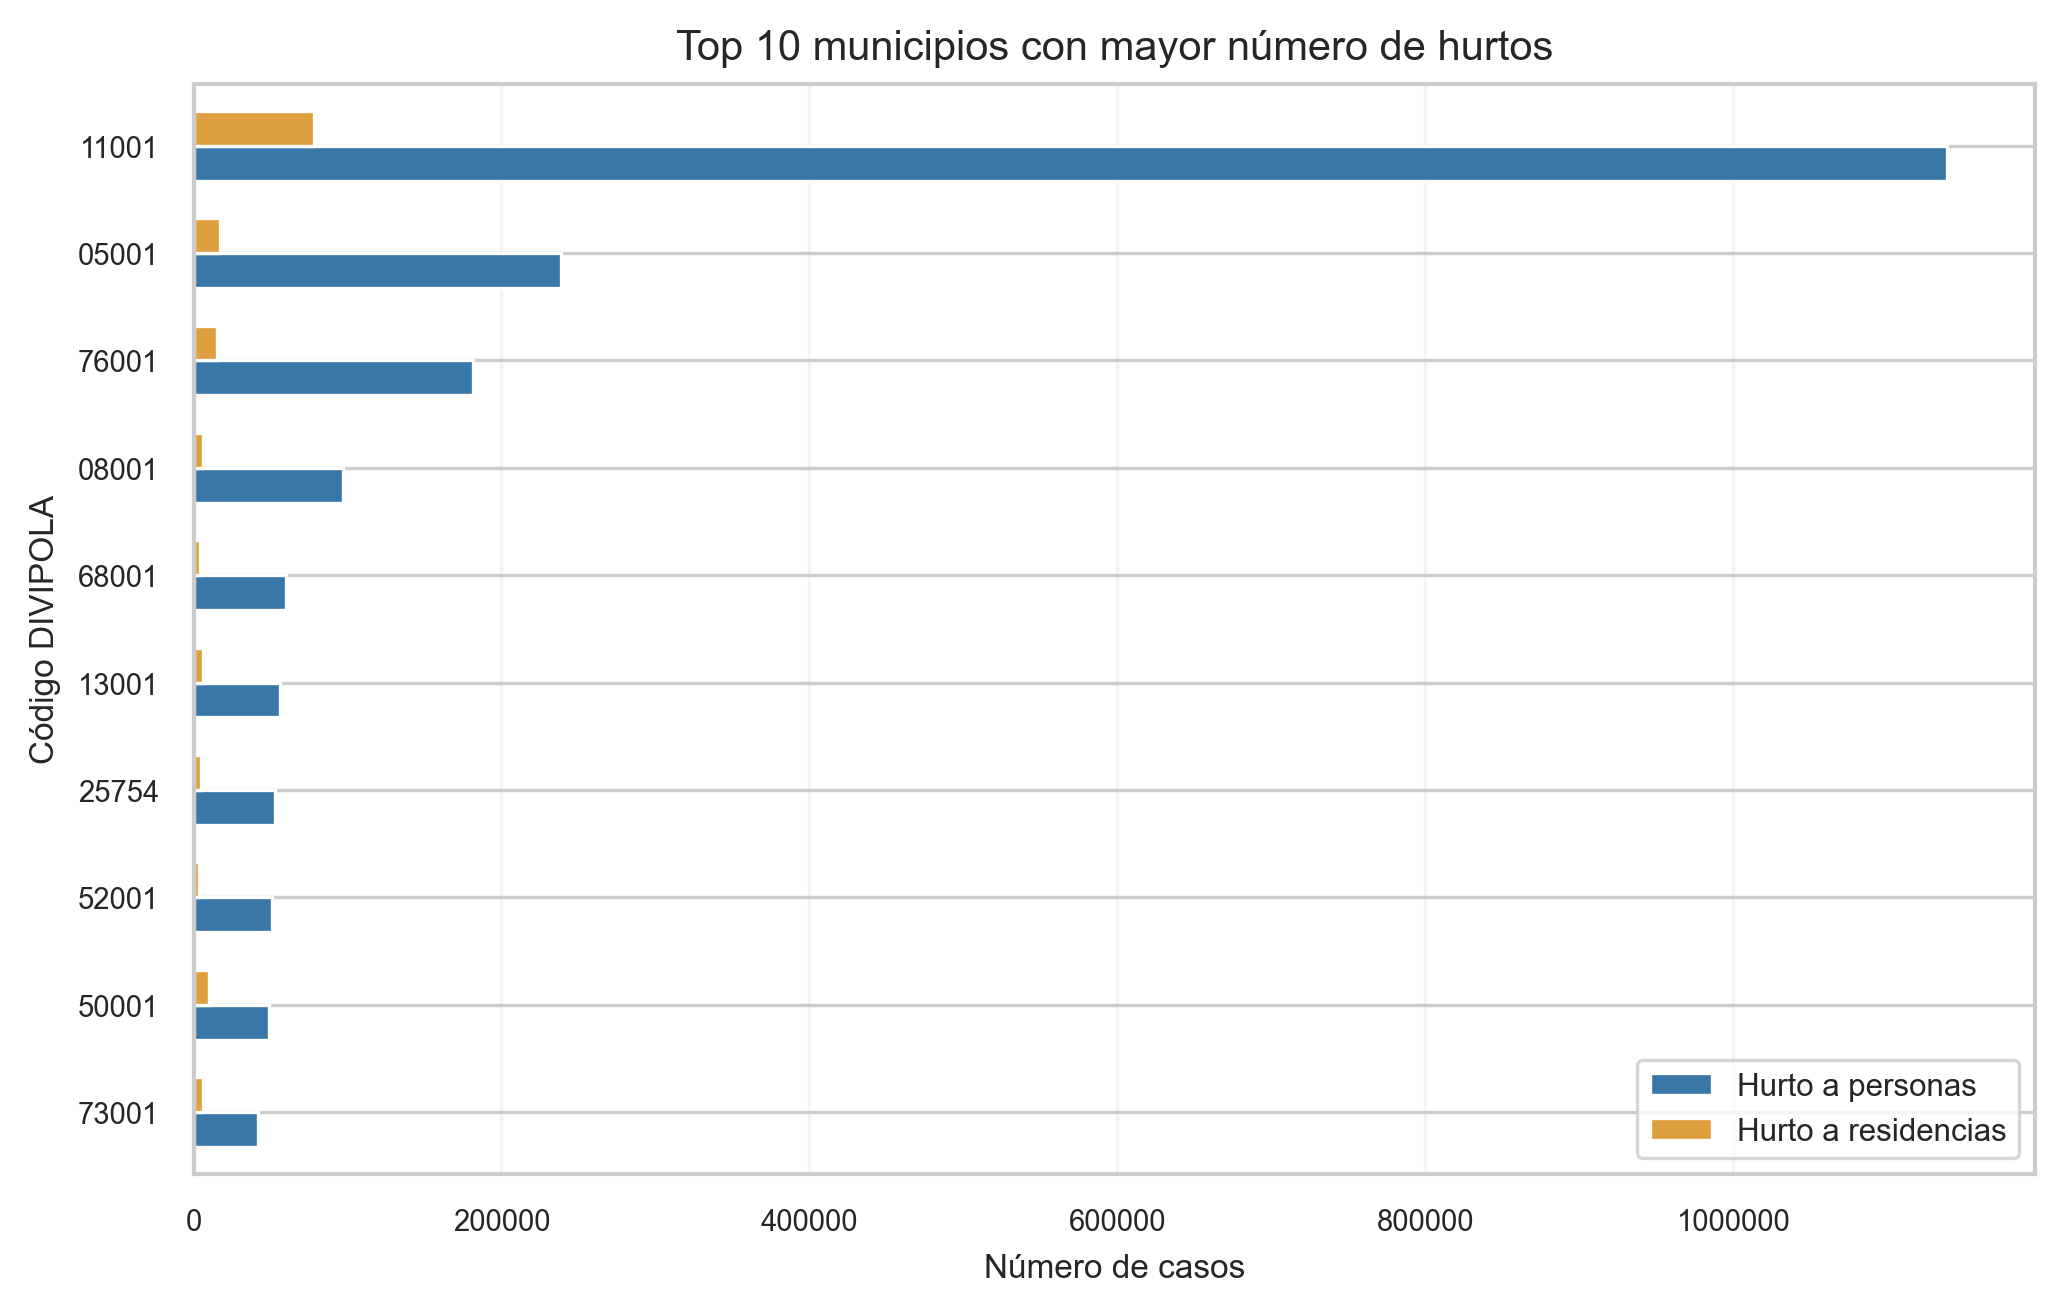

In [108]:
from matplotlib.ticker import ScalarFormatter

ax = top_municipios.plot(
    x="codigo_dane",
    y=["hurto_personas", "hurto_residencias"],
    kind="barh",
    figsize=(7, 4.5),
    color=["#3977A8", "#E09F3E"],
    width=0.65
)

ax.set_title("Top 10 municipios con mayor número de hurtos", fontsize=10)
ax.set_xlabel("Número de casos", fontsize=8)
ax.set_ylabel("Código DIVIPOLA", fontsize=8)
ax.tick_params(axis="both", labelsize=7)

ax.legend(["Hurto a personas", "Hurto a residencias"], fontsize=7.5)
ax.grid(axis="x", alpha=0.2)
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.ticklabel_format(axis="x", style="plain")

plt.tight_layout()
plt.show()

### Crear indicadores

,codigo_dane,anio,hurto_personas,hurto_residencias,total_hurtos,participacion_personas,participacion_residencias,log_hurto_personas,log_hurto_residencias
0,05001,2017,17825.0,1809.0,19634.0,0.907864,0.092136,9.788413,7.501082
1,05001,2018,21975.0,2135.0,24110.0,0.911448,0.088552,9.997706,7.666690
2,05001,2019,27263.0,2159.0,29422.0,0.926620,0.073380,10.213322,7.677864
3,05001,2020,17776.0,1703.0,19479.0,0.912573,0.087427,9.785661,7.440734
4,05001,2021,23703.0,1665.0,25368.0,0.934366,0.065634,10.073399,7.418181


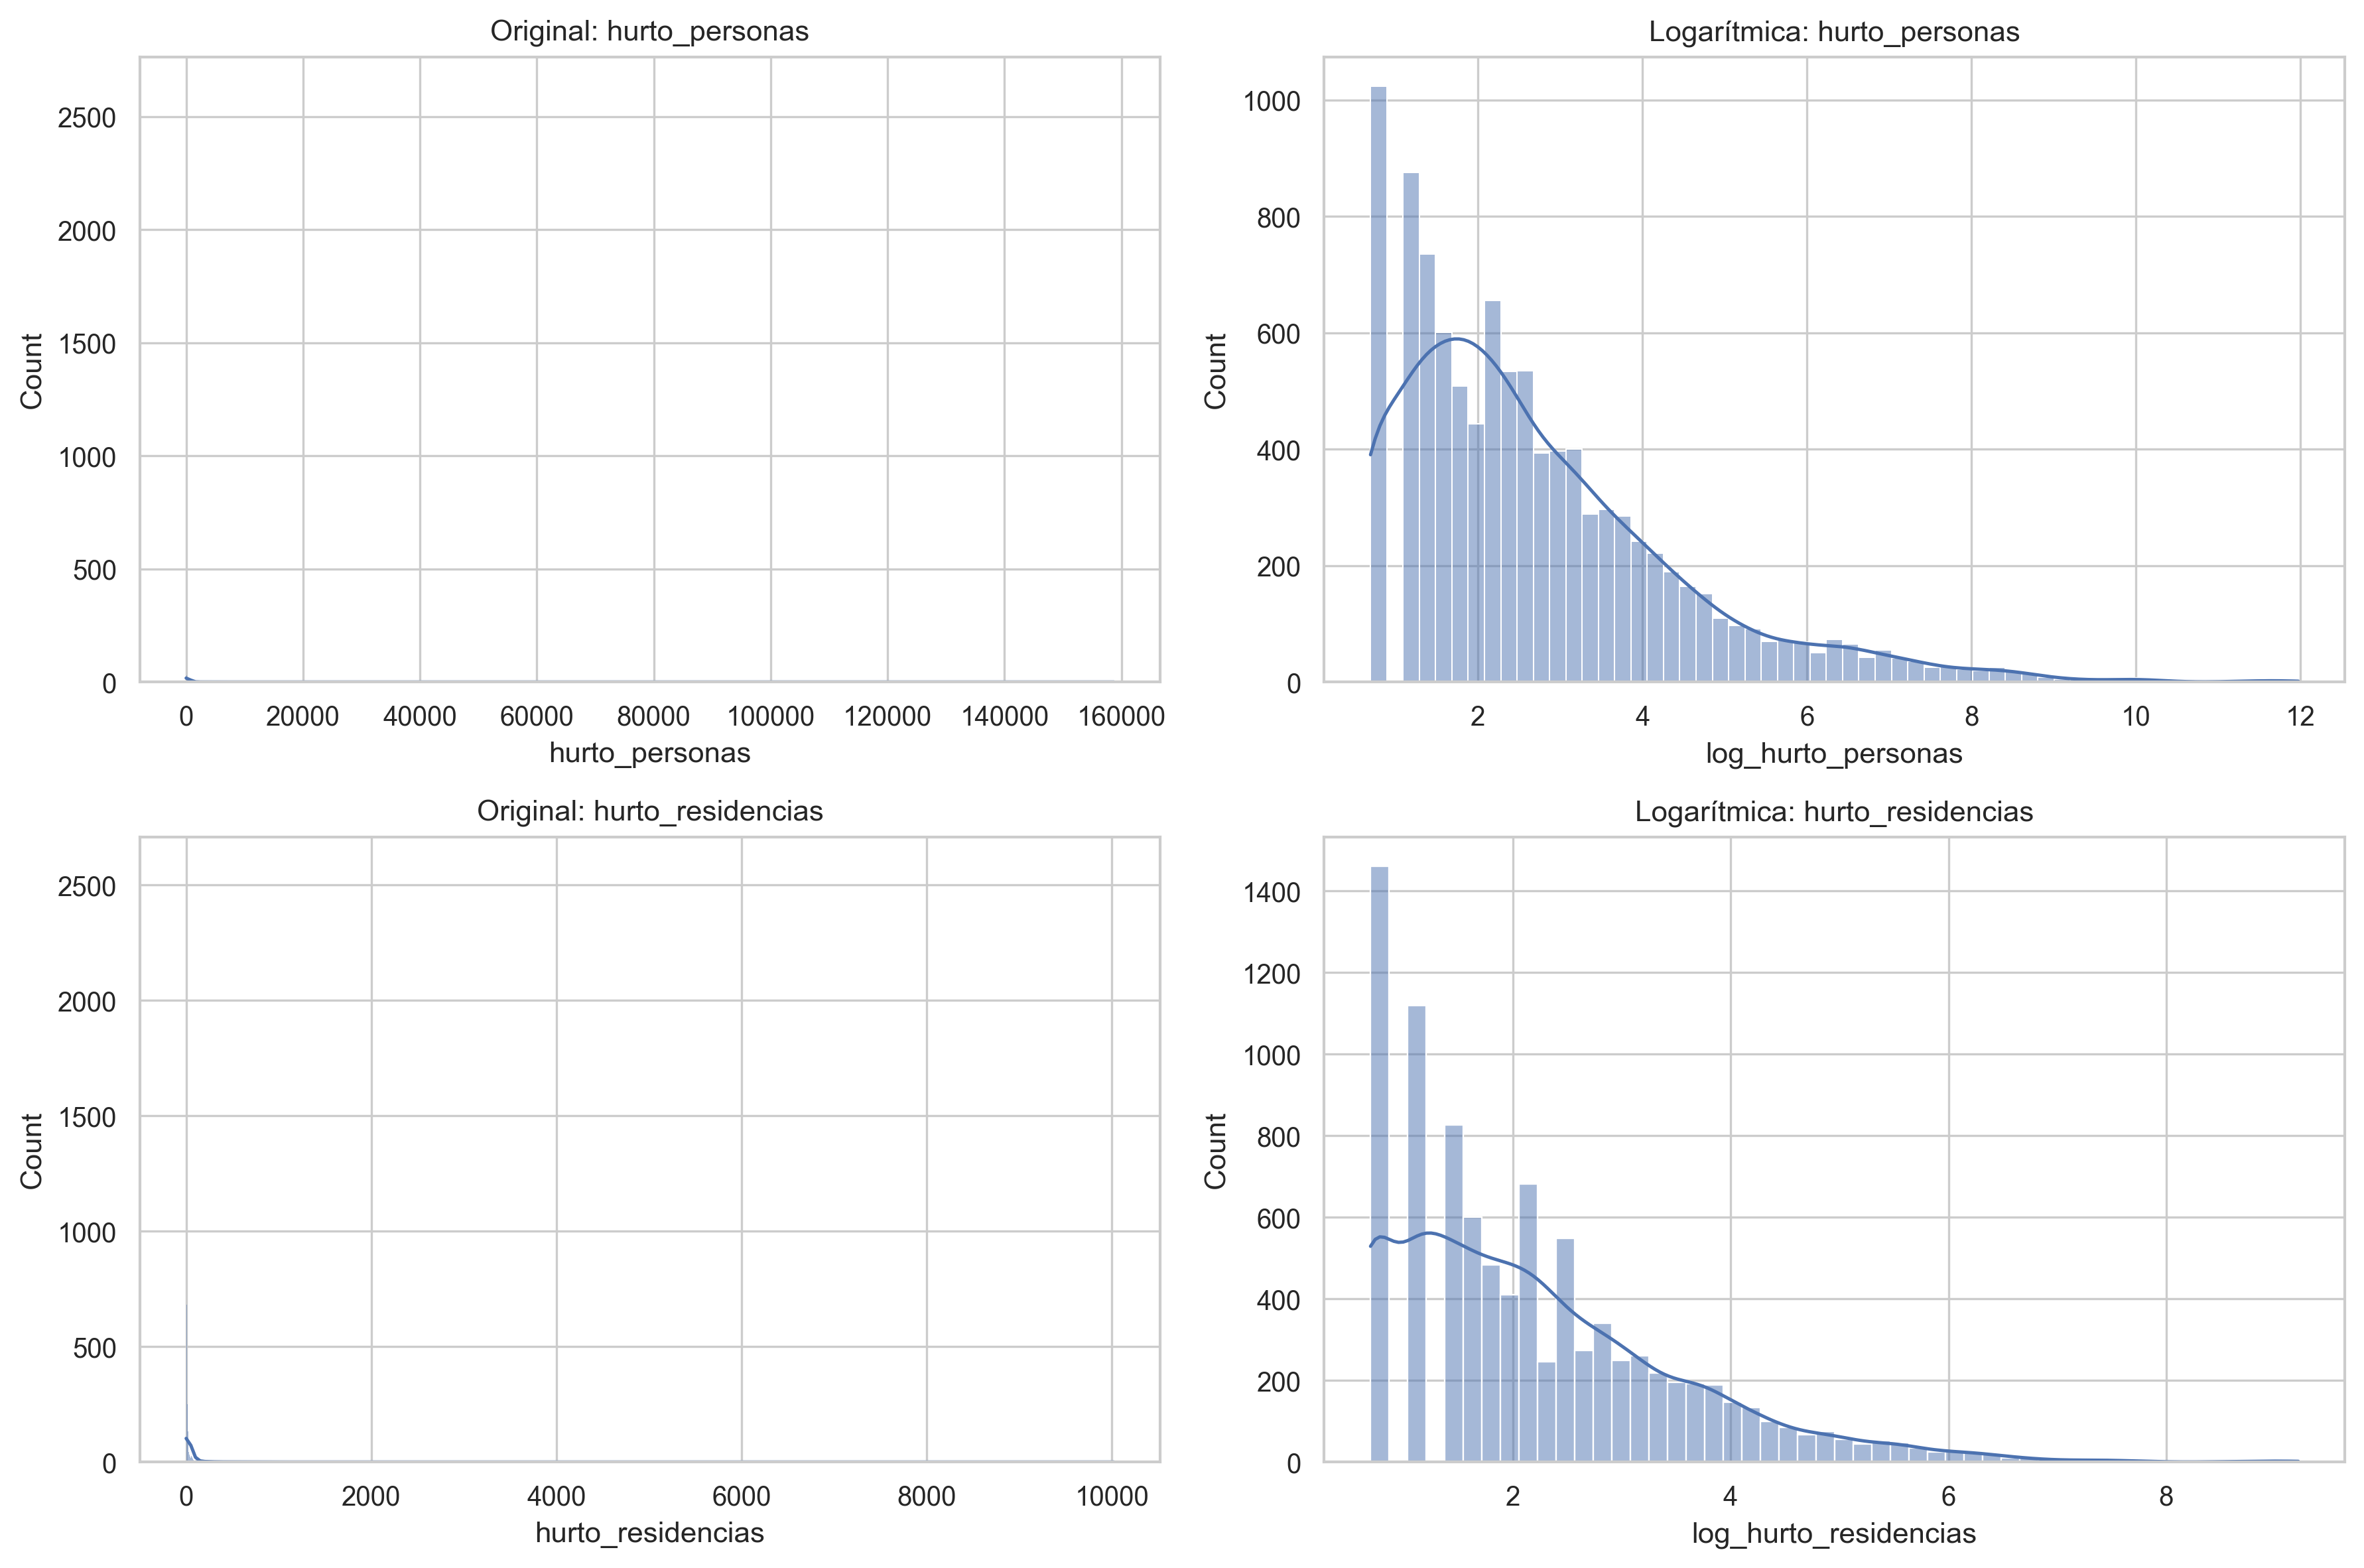

In [98]:
# Indicadores conjuntos: solo cuando ambas fuentes tienen información
df_eda["total_hurtos"] = df_eda[["hurto_personas", "hurto_residencias"]].sum(axis=1, min_count=2)

df_eda["participacion_personas"] = df_eda["hurto_personas"] / df_eda["total_hurtos"]

df_eda["participacion_residencias"] = df_eda["hurto_residencias"] / df_eda["total_hurtos"]

display(df_eda.head())


# Transformación logarítmica sin reemplazar variables originales
for col in columnas:
    df_eda[f"log_{col}"] = np.log1p(df_eda[col])

# Comparación de distribuciones
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, col in enumerate(columnas):
    sns.histplot(df_eda[col].dropna(), kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f"Original: {col}")

    sns.histplot(df_eda[f"log_{col}"].dropna(), kde=True, ax=axes[i, 1])
    axes[i, 1].set_title(f"Logarítmica: {col}")

plt.tight_layout()
plt.show()

una concentración de observaciones en valores bajos y una cola larga hacia los valores altos.

Esto puede ocurrir porque existen municipios o periodos con cantidades de hurtos considerablemente superiores a los demás.

### Conclusiones

El análisis de los datos de hurto a personas y residencias permitió identificar diferencias en los niveles de inseguridad entre los municipios colombianos, así como variaciones en la disponibilidad de información según las fuentes y los periodos analizados.

Los indicadores construidos facilitan la comparación territorial y la identificación de patrones de criminalidad. Para lograr una interpretación más precisa, es importante complementar los registros absolutos con tasas de hurto por cada 100.000 habitantes.

Desde el enfoque del negocio, la seguridad representa una dimensión importante para evaluar el potencial de los municipios en el desarrollo de proyectos de vivienda, ya que puede influir en la percepción de seguridad, la demanda residencial y el riesgo comercial.

Durante el tratamiento de los datos se priorizó conservar la información original, mantener los valores extremos y diferenciar los registros en cero de los datos faltantes, evitando modificaciones que pudieran generar sesgos en el análisis.

En conclusión, la información de seguridad complementa las variables demográficas, socioeconómicas e inmobiliarias y contribuye a construir una herramienta más integral para priorizar municipios. Sin embargo, no debe analizarse de manera aislada, sino como parte de una evaluación conjunta que permita identificar oportunidades de inversión y reducir riesgos de baja demanda e inmovilización de capital.